# 08 · Model comparison

This notebook puts every team model side by side and answers three questions:
1. **Which model is most accurate on a battery it has never seen?**
2. **Is the difference real, or just luck?**
3. **Where does each model go wrong?**

**Nothing is retrained here.** We read the saved out-of-fold predictions from each teammate's notebook and score them all the same way.
All three notebooks used the shared protocol (`src/evaluation.py`, notebook 05), so the folds, rows and inputs are identical.

| Source notebook | Models | File |
|---|---|---|
| `07_baselines` | Mean, one-feature, MLR, Ridge, Lasso, ElasticNet | `results/baselines/oof_baselines.csv` |
| `04_nonlinear_models` | SVR, Gaussian process (+ a Ridge copy) | `results/nonlinear_svr_gpr/oof_predictions.csv` |
| `06_modelling_random_forest_hgb` | Random forest, HistGradientBoosting | `results/modelling_random_forest_hgb/oof_rf_hgb.csv` |

**How to read the scores:** MAE is in **SOH points**. An MAE of 4 means predictions are off by 4 percentage points of health on average. Lower is better.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import (mean_absolute_error as mae, root_mean_squared_error as rmse, r2_score,
                             f1_score, recall_score, confusion_matrix)
from src import evaluation as ev

pd.set_option("display.width", 180)
OUT = ROOT / "results" / "model_comparison"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# One colour per model family (reference palette): grey = baselines, blue = linear, orange = non-linear
FAMILY_COLOR = {"baseline": "#8a8984", "linear": "#2a78d6", "non-linear": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#9ec5f4", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10})

## 1. Load everyone's predictions and check they match

In [2]:
FILES = {
    "07_baselines":   ROOT / "results/baselines/oof_baselines.csv",
    "04_nonlinear":   ROOT / "results/nonlinear_svr_gpr/oof_predictions.csv",
    "06_rf_hgb":      ROOT / "results/modelling_random_forest_hgb/oof_rf_hgb.csv",
}
raw = pd.concat([pd.read_csv(p).assign(source=k) for k, p in FILES.items()], ignore_index=True)

# Same rows, same true SOH, same folds as the fixed fold file?
folds = pd.read_csv(ev.OUT_DIR / "fold_assignment.csv")
checks = {}
for (src, model, scheme), g in raw.groupby(["source", "model", "scheme"]):
    j = g.merge(folds, on=["cell_id", "idtest"], how="left")
    checks[(src, model, scheme)] = len(g) == 306 and (j.fold == j[f"fold_{scheme}"]).all()
assert all(checks.values()), [k for k, v in checks.items() if not v]
# same truth in every file (rounded: files written on different machines differ by ~1e-14)
assert raw.y_true.round(9).groupby([raw.cell_id, raw.idtest]).nunique().max() == 1
print(f"{raw.groupby(['model', 'scheme']).ngroups} model x split runs, all with 306 rows, identical truth and identical folds")

39 model x split runs, all with 306 rows, identical truth and identical folds


In [3]:
# Ridge was run twice (07 'Ridge (tuned)' and 04 'Ridge'). Same predictions? Then keep one.
r = raw[raw.model.isin(["Ridge", "Ridge (tuned)"])].pivot_table(index=["cell_id", "idtest", "scheme"],
                                                                 columns="model", values="y_pred")
print("largest difference between the two Ridge runs:", float((r["Ridge"] - r["Ridge (tuned)"]).abs().max()))

# Keep the baselines notebook's Ridge copy. The post-hoc GP kernel fix from notebook 04 is not part of the
# pre-declared comparison; its result is quoted in Section 7.
oof = raw[~raw.model.isin(["Ridge", "GP linear+RBF (post-hoc)"])].copy()
oof["model"] = oof.model.replace({"Ridge (tuned)": "Ridge", "Lasso (tuned)": "Lasso",
                                  "ElasticNet (tuned)": "ElasticNet", "Mean SOH (training cells)": "Mean baseline",
                                  "MLR (pruned main set)": "MLR", "HistGradientBoosting": "Gradient boosting (HGB)"})
FAMILY = {"Mean baseline": "baseline", "One feature: cum_EFC": "baseline", "One feature: days_since_start": "baseline",
          "MLR": "linear", "Ridge": "linear", "Lasso": "linear", "ElasticNet": "linear",
          "SVR (RBF)": "non-linear", "Gaussian process": "non-linear",
          "Random forest": "non-linear", "Gradient boosting (HGB)": "non-linear"}
assert set(oof.model) == set(FAMILY), set(oof.model) ^ set(FAMILY)
oof["family"] = oof.model.map(FAMILY)
loco = oof[oof.scheme == "LOCO"]
print(len(FAMILY), "models kept:", sorted(FAMILY))

largest difference between the two Ridge runs: 2.0179413695586845e-12
11 models kept: ['ElasticNet', 'Gaussian process', 'Gradient boosting (HGB)', 'Lasso', 'MLR', 'Mean baseline', 'One feature: cum_EFC', 'One feature: days_since_start', 'Random forest', 'Ridge', 'SVR (RBF)']


**Check passed.** All 39 runs (13 models × 3 splits, counting Ridge twice and notebook 04's post-hoc GP) cover the same 306 rows, with the same true SOH and the same folds, so the comparison is fair.

The two Ridge runs are the same model: their predictions differ by about 0.000000000002 (rounding noise). We keep one.

## 2. The main table: accuracy on unseen batteries (leave-one-cell-out)

* **MAE** = average miss, in SOH points (headline)
* **RMSE** = like MAE, but punishes big misses more
* **R²** = share of the variation explained (1 = perfect, 0 = no better than guessing the average)
* **Max error** = the single worst miss
* **Within 5 / 10 pts** = share of predictions within 5 or 10 SOH points of the truth
* **Relative accuracy** = 100 − average % error (same definition as notebook 06)

In [4]:
def scores(g):
    y, p = g.y_true.to_numpy(), g.y_pred.to_numpy()
    err = np.abs(p - y)
    return pd.Series({"MAE": mae(y, p), "RMSE": rmse(y, p), "R2": r2_score(y, p), "Max error": err.max(),
                      "Within 5 pts %": 100 * (err <= 5).mean(), "Within 10 pts %": 100 * (err <= 10).mean(),
                      "Relative accuracy %": 100 - 100 * (err / y).mean()})

all_scores = oof.groupby(["model", "scheme"]).apply(scores).reset_index()
all_scores["family"] = all_scores.model.map(FAMILY)
main = (all_scores[all_scores.scheme == "LOCO"].drop(columns="scheme")
        .sort_values("MAE").set_index("model"))
main.round(2)

,MAE,RMSE,R2,Max error,Within 5 pts %,Within 10 pts %,Relative accuracy %,family
model,,,,,,,,
ElasticNet,4.25,7.08,0.59,51.89,74.84,90.20,94.05,linear
Gradient boosting (HGB),4.27,7.72,0.52,46.28,75.82,88.56,93.81,non-linear
Lasso,4.51,7.88,0.50,57.58,74.18,83.66,93.59,linear
Random forest,4.65,8.67,0.39,55.48,75.82,82.68,93.27,non-linear
Ridge,4.76,7.63,0.53,49.88,72.88,88.24,93.50,linear
SVR (RBF),4.81,8.20,0.45,56.38,73.86,87.25,93.09,non-linear
MLR,5.85,8.55,0.41,45.76,61.76,83.33,92.43,linear
One feature: days_since_start,7.26,10.38,0.13,53.23,52.61,79.08,90.16,baseline
Gaussian process,7.72,12.77,-0.32,56.06,61.76,76.47,89.72,non-linear


**What this says**
* **Top two:** ElasticNet (4.25) and gradient boosting (4.27) are the most accurate on unseen batteries, about half the error of the mean baseline (8.18).
* **A middle group:** Lasso, random forest, Ridge and SVR sit close behind, between 4.5 and 4.8.
* **Plain MLR is clearly worse (5.85).** With no regularisation, its correlated inputs push the coefficients around.
* **The Gaussian process (7.72) barely beats guessing the average.** Section 2a shows why.
* **About "relative accuracy":** it sounds great (about 94% for the top models), but the mean baseline already scores 89%, because SOH sits between 33 and 100%. Report MAE and "within 5 points" instead. They're easier to read and harder to misread.

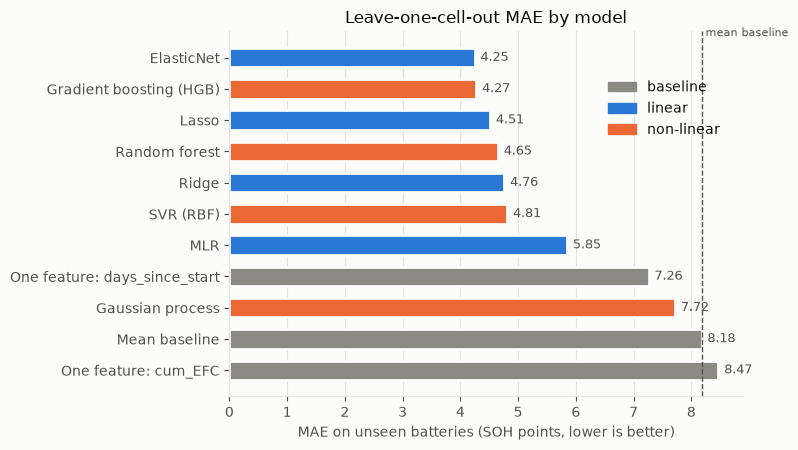

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.6))
m = main.sort_values("MAE", ascending=False)
ax.barh(m.index, m.MAE, color=[FAMILY_COLOR[f] for f in m.family], height=0.62, edgecolor="#fcfcfb", linewidth=2)
for y, v in enumerate(m.MAE):
    ax.text(v + 0.1, y, f"{v:.2f}", va="center", fontsize=9, color=MUTED)
base = main.loc["Mean baseline", "MAE"]
ax.axvline(base, color=MUTED, lw=1, ls="--")
ax.text(base, len(m) - 0.4, " mean baseline", color=MUTED, fontsize=8, va="bottom")
ax.set(xlabel="MAE on unseen batteries (SOH points, lower is better)", title="Leave-one-cell-out MAE by model")
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLOR.values()],
          labels=list(FAMILY_COLOR), loc="upper right", bbox_to_anchor=(0.98, 0.9), frameon=False)
fig.tight_layout(); fig.savefig(FIG / "loco_mae_by_model.png", dpi=150); plt.show()

### 2a. The same models under the other two splits

* **LOPO** = leave a whole *profile* out (harder: new operating conditions)
* **Random 5-fold** = rows shuffled at random (too easy: neighbouring check-ups of the same battery leak into training)
* **Gap** = LOCO MAE − random MAE. A big gap means the model looks great on random splits but doesn't transfer to new batteries.

In [6]:
splits = all_scores.pivot(index="model", columns="scheme", values="MAE")[["LOCO", "LOPO", "Random 5-fold"]]
splits["Gap (LOCO - random)"] = splits["LOCO"] - splits["Random 5-fold"]
splits = splits.loc[main.index]
splits.round(2)

scheme,LOCO,LOPO,Random 5-fold,Gap (LOCO - random)
model,,,,
ElasticNet,4.25,4.45,2.79,1.45
Gradient boosting (HGB),4.27,4.49,1.63,2.65
Lasso,4.51,4.90,2.77,1.74
Random forest,4.65,4.46,2.05,2.61
Ridge,4.76,4.89,2.79,1.97
SVR (RBF),4.81,5.87,1.24,3.57
MLR,5.85,6.24,2.85,3.00
One feature: days_since_start,7.26,7.33,6.87,0.39
Gaussian process,7.72,8.13,1.30,6.42


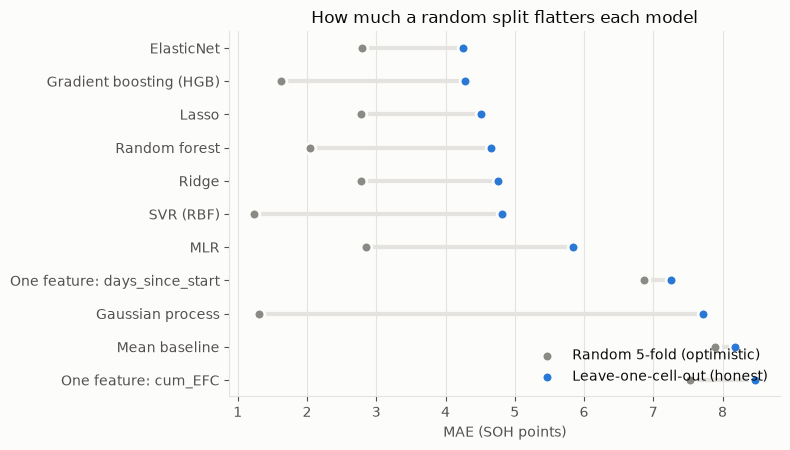

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.6))
s = splits.sort_values("LOCO", ascending=False)
yy = np.arange(len(s))
ax.hlines(yy, s["Random 5-fold"], s["LOCO"], color=GRID, lw=3)
ax.scatter(s["Random 5-fold"], yy, s=60, color="#8a8984", zorder=3, label="Random 5-fold (optimistic)",
           edgecolor="#fcfcfb", linewidth=2)
ax.scatter(s["LOCO"], yy, s=60, color="#2a78d6", zorder=3, label="Leave-one-cell-out (honest)",
           edgecolor="#fcfcfb", linewidth=2)
ax.set_yticks(yy, s.index)
ax.set(xlabel="MAE (SOH points)", title="How much a random split flatters each model")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(FIG / "random_vs_loco_gap.png", dpi=150); plt.show()

**Random splits flatter every model that learns something.** The two baselines barely move (gap below 1), because they have nothing to memorise.
* **Gaussian process:** looks like the best model on a random split (1.30) and is nearly the worst on new batteries (7.72). It memorises each battery's curve and falls back to the average when it meets a new one.
* **SVR and the tree models:** gaps of 2.6–3.6. They also lean on battery-specific patterns.
* **ElasticNet:** the smallest gap of the real models (1.45). Its random-split score is closest to what it actually delivers.

This is the main reliability point for the report: **a random split would have picked the wrong model.**

## 3. Is the difference real? Paired tests on the same 15 folds

Every model was tested on the same 15 held-out batteries, so we compare them **battery by battery**:
* **Wins** = held-out batteries where the model beats the reference
* **Wilcoxon p** = how likely a difference this consistent is by chance
* **Holm p** = the same p-value, adjusted because we run many tests at once. **Use this one.** Below 0.05 counts as a real difference.

In [8]:
fold_mae = loco.groupby(["model", "fold"]).apply(lambda g: mae(g.y_true, g.y_pred)).unstack(0)
best = main.index[0]
rows = []
for ref in [best, "Ridge"]:
    for m in main.index:
        if m == ref:
            continue
        rows.append(dict(model=m, reference=ref, **ev.paired_test(fold_mae[m], fold_mae[ref])))
paired = pd.DataFrame(rows)
paired["holm_p"] = ev.holm(paired.wilcoxon_p)
paired = paired.rename(columns={"a_wins": "model wins", "b_wins": "reference wins",
                                "mean_diff": "MAE diff (model - ref)"})
print("best model on LOCO:", best)
paired.round(3)

best model on LOCO: ElasticNet


,model,reference,n_folds,MAE diff (model - ref),model wins,reference wins,ties,wilcoxon_p,holm_p
0,Gradient boosting (HGB),ElasticNet,15,0.024,8,7,0,0.489,1.000
1,Lasso,ElasticNet,15,0.379,7,8,0,0.389,1.000
2,Random forest,ElasticNet,15,0.433,8,7,0,1.000,1.000
3,Ridge,ElasticNet,15,0.455,5,10,0,0.026,0.332
4,SVR (RBF),ElasticNet,15,0.845,4,11,0,0.055,0.498
5,MLR,ElasticNet,15,2.029,2,13,0,0.010,0.164
6,One feature: days_since_start,ElasticNet,15,3.576,3,12,0,0.015,0.226
7,Gaussian process,ElasticNet,15,3.667,3,12,0,0.008,0.151
8,Mean baseline,ElasticNet,15,4.265,1,14,0,0.002,0.040
9,One feature: cum_EFC,ElasticNet,15,4.631,2,13,0,0.008,0.151


**After correcting for multiple tests, none of the top six models is significantly better than another.**
* **ElasticNet vs gradient boosting:** 8 to 7 battery wins. A coin flip.
* **ElasticNet vs Ridge:** ElasticNet wins 10 of 15 batteries (raw p = 0.026), but that disappears after the Holm correction (0.33).
* **ElasticNet vs the mean baseline:** the only comparison that holds up (14 of 15 wins, Holm p = 0.04).

With only 15 test batteries, differences under about 0.5 MAE can't be told apart from luck. **Treat the top group as a tie.** Choose between them on reliability and simplicity, not on the second decimal.

## 4. Where do the models go wrong?

Two splits of the same leave-one-cell-out predictions:
* **Regime:** is the held-out battery's operating profile *inside* the range the model trained on (interpolation) or *outside* it (extrapolation)?
* **Health class:** Healthy (≥ 90), Degraded (80–90), EOL risk (< 80)

In [9]:
def by(col):
    t = loco.groupby(["model", col], observed=True).apply(lambda g: mae(g.y_true, g.y_pred)).unstack(col)
    return t.loc[main.index]

regime = by("regime")[["interpolation", "extrapolation", "unclassified"]]
health = by("health_class")[["Healthy (>=90)", "Degraded (80-90)", "EOL risk (<80)"]]
bias = loco.groupby(["model", "health_class"], observed=True).apply(lambda g: (g.y_pred - g.y_true).mean()) \
           .unstack("health_class").loc[main.index, ["Healthy (>=90)", "Degraded (80-90)", "EOL risk (<80)"]]
print("MAE by regime (rows:", loco[loco.model == best].regime.value_counts().to_dict(), ")")
display(regime.round(2))
print("MAE by health class (rows:", loco[loco.model == best].health_class.value_counts().to_dict(), ")")
display(health.round(2))
print("Bias by health class (+ = predicts too healthy)")
display(bias.round(2))

MAE by regime (rows: {'interpolation': 219, 'extrapolation': 66, 'unclassified': 21} )


regime,interpolation,extrapolation,unclassified
model,,,
ElasticNet,2.54,9.66,5.00
Gradient boosting (HGB),2.33,10.74,4.21
Lasso,2.39,11.62,4.32
Random forest,2.10,13.63,3.06
Ridge,3.09,10.27,4.91
SVR (RBF),2.80,10.96,6.46
MLR,4.33,11.50,3.95
One feature: days_since_start,5.43,13.38,7.05
Gaussian process,3.79,20.55,8.36


MAE by health class (rows: {'Healthy (>=90)': 187, 'Degraded (80-90)': 66, 'EOL risk (<80)': 53} )


health_class,Healthy (>=90),Degraded (80-90),EOL risk (<80)
model,,,
ElasticNet,3.16,2.52,10.22
Gradient boosting (HGB),2.02,3.38,13.36
Lasso,3.19,2.56,11.61
Random forest,2.70,2.67,14.00
Ridge,3.63,3.69,10.10
SVR (RBF),2.99,3.30,13.11
MLR,4.82,5.21,10.28
One feature: days_since_start,5.09,4.99,17.74
Gaussian process,5.85,6.07,16.37


Bias by health class (+ = predicts too healthy)


health_class,Healthy (>=90),Degraded (80-90),EOL risk (<80)
model,,,
ElasticNet,-2.51,-1.63,9.32
Gradient boosting (HGB),-1.36,-0.78,8.57
Lasso,-2.05,-1.24,10.83
Random forest,-1.82,-0.19,10.52
Ridge,-1.64,-2.35,9.22
SVR (RBF),-1.50,-0.68,12.56
MLR,-0.26,-1.16,9.00
One feature: days_since_start,-4.76,-0.97,17.74
Gaussian process,-4.10,-0.82,15.80


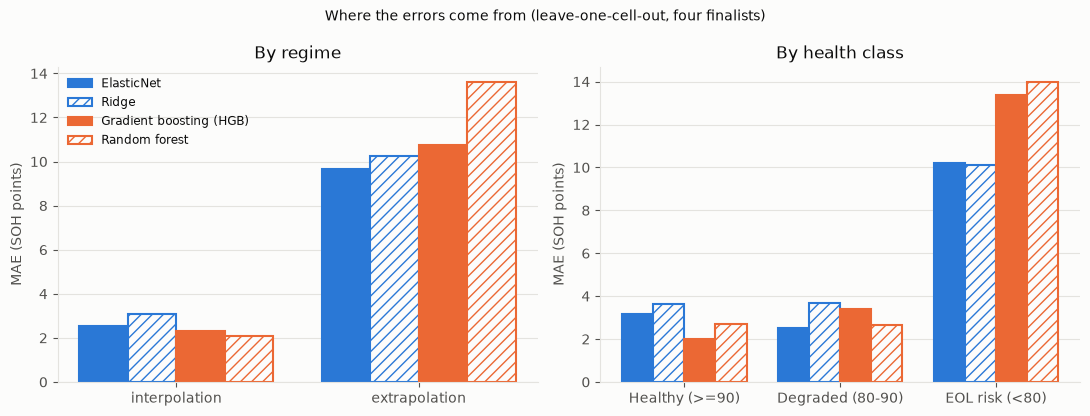

In [10]:
FINALISTS = ["ElasticNet", "Ridge", "Gradient boosting (HGB)", "Random forest"]
STYLE = {"ElasticNet": ("#2a78d6", None), "Ridge": ("#2a78d6", "///"),
         "Gradient boosting (HGB)": ("#eb6834", None), "Random forest": ("#eb6834", "///")}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (tab, title) in zip(axes, [(regime[["interpolation", "extrapolation"]], "By regime"),
                                   (health, "By health class")]):
    t = tab.loc[FINALISTS]
    x = np.arange(t.shape[1]); w = 0.8 / len(FINALISTS)
    for i, mname in enumerate(FINALISTS):
        colour, hatch = STYLE[mname]
        bars = ax.bar(x + i * w - 0.4 + w / 2, t.loc[mname], width=w, color=colour if hatch is None else "#fcfcfb",
                      edgecolor=colour, hatch=hatch, linewidth=1.5, label=mname)
    ax.set_xticks(x, t.columns)
    ax.set(ylabel="MAE (SOH points)", title=title)
    ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=8.5, loc="upper left")
fig.suptitle("Where the errors come from (leave-one-cell-out, four finalists)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "error_by_regime_and_health.png", dpi=150); plt.show()

**This is where linear and non-linear models really differ.**
* **Familiar conditions (interpolation):** all models do well, 2–3 points. Random forest is best (2.10).
* **Unfamiliar conditions (extrapolation):** errors jump to 10–14 points. ElasticNet holds up best (9.66). Random forest is the worst of the top models (13.63), because trees can't predict outside the values they were trained on.
* **Healthy batteries:** gradient boosting is best (2.02).
* **Worn-out batteries (EOL < 80%):** every model misses by 10+ points, and the bias table shows they all guess **too healthy** (+8.6 to +12.6). Ridge and ElasticNet miss the least (about 10); the tree models and SVR miss 13–14.

**In short:** the non-linear models are sharper on familiar, healthy batteries. The linear models are safer on new conditions and worn-out batteries, which are the cases that matter most for safety.

### 4a. Error for each held-out battery

Each cell of the heatmap is one model tested on one unseen battery. Darker means a bigger miss.

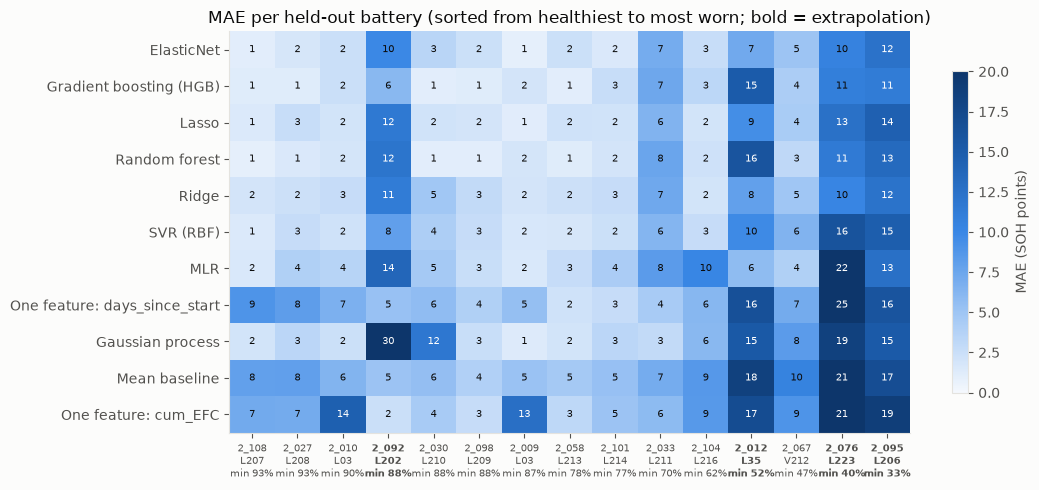

In [11]:
cell_info = (loco.groupby("cell_id").agg(profile=("profile", "first"), regime=("regime", "first"),
                                         min_SOH=("y_true", "min")))
per_cell = loco.groupby(["model", "cell_id"]).apply(lambda g: mae(g.y_true, g.y_pred)).unstack("cell_id")
order = cell_info.sort_values("min_SOH", ascending=False).index
per_cell = per_cell.loc[main.index, order]

fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(per_cell.to_numpy(), cmap=BLUES, aspect="auto", vmin=0, vmax=20)
ax.set_xticks(range(len(order)), [f"{c}\n{cell_info.profile[c]}\nmin {cell_info.min_SOH[c]:.0f}%" for c in order],
              fontsize=7.5)
ax.set_yticks(range(len(per_cell)), per_cell.index)
for i in range(per_cell.shape[0]):
    for j in range(per_cell.shape[1]):
        v = per_cell.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 11 else INK)
for j, c in enumerate(order):
    if cell_info.regime[c] == "extrapolation":
        ax.get_xticklabels()[j].set_fontweight("bold")
ax.grid(False)
ax.set_title("MAE per held-out battery (sorted from healthiest to most worn; bold = extrapolation)")
fig.colorbar(im, ax=ax, label="MAE (SOH points)", shrink=0.8)
fig.tight_layout(); fig.savefig(FIG / "mae_per_battery_heatmap.png", dpi=150); plt.show()

In [12]:
hardest = per_cell.loc[[m for m in main.index if FAMILY[m] != "baseline"]].median().sort_values(ascending=False)
pd.DataFrame({"median MAE across models": hardest.round(2)}).join(cell_info).head(6)

,median MAE across models,profile,regime,min_SOH
cell_id,,,,
2_095,12.97,L206,extrapolation,33.264196
2_076,11.98,L223,extrapolation,40.058105
2_092,11.39,L202,extrapolation,88.204835
2_012,9.57,L35,extrapolation,51.506836
2_033,7.12,L211,interpolation,70.239678
2_067,4.62,V212,unclassified,47.000836


**Most of the error comes from four batteries, all of them extrapolation cases:**
* **2_095** (L206): stored at 45 °C and 95% charge, higher than any other profile; falls to 33% SOH
* **2_076** (L223): the only profile charged at 0.5C (all others ≤ 0.2C)
* **2_092** (L202): stored at 45 °C and only 15% charge, lower than any other profile
* **2_012** (L35): its `lp_F` setting is 0.5, while every other profile has 0.25 or less

Each was aged under conditions no other battery in the training set covers, so no model can learn them from the data we have. On the other 11 batteries, the good models are typically within 1–3 points.

**Worth noting:** gradient boosting and random forest do much worse than ElasticNet on 2_012 (15–16 vs 7), while ElasticNet does worse on 2_092 (10 vs 6). There is no single winner on every battery.

### 4b. Predicted vs true SOH (best linear and best non-linear model)

Points on the diagonal are perfect predictions. Points **above** the line mean the model thinks the battery is healthier than it really is (the risky direction).

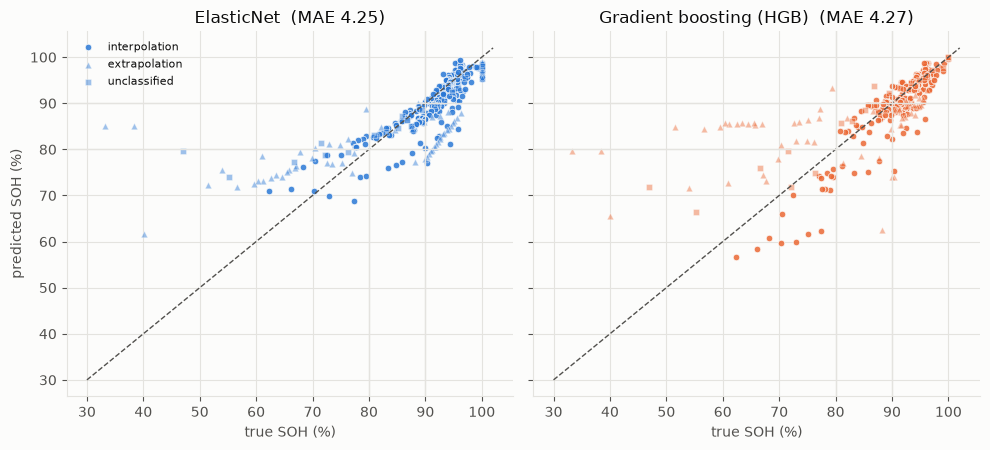

In [13]:
best_lin = next(m for m in main.index if FAMILY[m] == "linear")
best_nl = next(m for m in main.index if FAMILY[m] == "non-linear")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, mname in zip(axes, [best_lin, best_nl]):
    g = loco[loco.model == mname]
    for reg, mk in [("interpolation", "o"), ("extrapolation", "^"), ("unclassified", "s")]:
        h = g[g.regime == reg]
        ax.scatter(h.y_true, h.y_pred, s=22, marker=mk, color=FAMILY_COLOR[FAMILY[mname]],
                   alpha=0.85 if reg == "interpolation" else 0.45, edgecolor="#fcfcfb", linewidth=0.6, label=reg)
    ax.plot([30, 102], [30, 102], color=MUTED, lw=1, ls="--")
    for t in (80, 90):
        ax.axvline(t, color=GRID, lw=1); ax.axhline(t, color=GRID, lw=1)
    ax.set(title=f"{mname}  (MAE {main.loc[mname, 'MAE']:.2f})", xlabel="true SOH (%)")
axes[0].set_ylabel("predicted SOH (%)")
axes[0].legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout(); fig.savefig(FIG / "predicted_vs_true.png", dpi=150); plt.show()

**Both models squash the extremes.** Above 85% SOH they track the diagonal closely. Below 70% they flatten out and predict 70–85% for batteries that are really at 33–60% (the triangles, mostly extrapolation cells). That's the "too healthy" bias from Section 4.

Gradient boosting also has a band of points stuck at about 85%: a tree can't predict beyond the leaves it learned, so it caps out.

## 5. Classification view: turn predicted SOH into health classes

This uses the same predictions, cut at 80 and 90, so Shraddha's classification can be compared on the same footing.
* **Macro-F1** gives each class equal weight, so the small EOL class counts as much as the big Healthy class.
* **EOL recall** = the share of truly worn-out check-ups (SOH < 80) the model flags as EOL. Missing them is the costly error.

In [14]:
labels = ["EOL risk (<80)", "Degraded (80-90)", "Healthy (>=90)"]
to_class = lambda s: pd.cut(s, ev.HEALTH_BINS, right=False, labels=labels)
cls = []
for mname, g in loco.groupby("model"):
    t, p = to_class(g.y_true), to_class(g.y_pred)
    cls.append(dict(model=mname, accuracy=(t == p).mean(), macro_F1=f1_score(t, p, average="macro"),
                    EOL_recall=recall_score(t, p, labels=[labels[0]], average="macro"),
                    EOL_missed=int(((t == labels[0]) & (p != labels[0])).sum())))
cls = pd.DataFrame(cls).set_index("model").loc[main.index]
cls.round(3)

,accuracy,macro_F1,EOL_recall,EOL_missed
model,,,,
ElasticNet,0.739,0.721,0.717,15
Gradient boosting (HGB),0.732,0.685,0.604,21
Lasso,0.755,0.726,0.698,16
Random forest,0.742,0.678,0.528,25
Ridge,0.755,0.732,0.755,13
SVR (RBF),0.716,0.659,0.491,27
MLR,0.693,0.649,0.660,18
One feature: days_since_start,0.458,0.353,0.057,50
Gaussian process,0.611,0.503,0.283,38


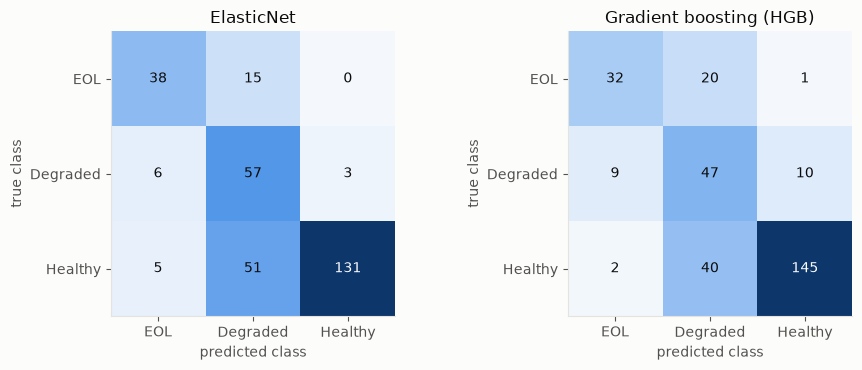

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8))
for ax, mname in zip(axes, [best_lin, best_nl]):
    g = loco[loco.model == mname]
    cm = confusion_matrix(to_class(g.y_true), to_class(g.y_pred), labels=labels)
    ax.imshow(cm, cmap=BLUES)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() * 0.55 else INK)
    short = ["EOL", "Degraded", "Healthy"]
    ax.set_xticks(range(3), short); ax.set_yticks(range(3), short)
    ax.set(xlabel="predicted class", ylabel="true class", title=mname); ax.grid(False)
fig.tight_layout(); fig.savefig(FIG / "confusion_matrices.png", dpi=150); plt.show()

**For health classes, Ridge and ElasticNet are the safest choice.**
* **Ridge** catches the most EOL batteries: 40 of 53 (recall 0.76). Its macro-F1 (0.73) is also the highest.
* **ElasticNet** is close behind (recall 0.72).
* **The non-linear models miss many more:** random forest misses 25 of 53, SVR misses 27.

The mean baseline flags none at all. A model that labels a worn-out battery "healthy" is the dangerous mistake, so this table favours the linear models, even though their MAE ties with gradient boosting.

**For Shraddha:** this is the regression-then-threshold baseline. A direct classifier should beat these numbers to be worth keeping.

## 6. Locked hold-out (notebook 01's 3 test batteries)

This is the course-style "final test set". The protocol says to score each **final** model on it once and never use it to choose models.

In [16]:
hold = pd.concat([pd.read_csv(ROOT / "results/baselines/holdout_check.csv"),
                  pd.read_csv(ROOT / "results/nonlinear_svr_gpr/holdout_check.csv"),
                  pd.read_csv(ROOT / "results/modelling_random_forest_hgb/holdout_check.csv")], ignore_index=True)
hold["model"] = hold.model.replace({"HistGradientBoosting": "Gradient boosting (HGB)",
                                    "ElasticNet (tuned)": "ElasticNet", "Ridge (tuned)": "Ridge"})
hold = hold.set_index("model")
hold["LOCO MAE on the same 3 batteries"] = [
    mae(*loco[(loco.model == m) & loco.cell_id.isin(["2_009", "2_092", "2_098"])][["y_true", "y_pred"]].T.to_numpy())
    for m in hold.index]
display(hold.round(2))
print("hold-out still missing for:", [m for m in FINALISTS if m not in hold.index])

,n_dev_cells,n_test,test_cells,MAE,RMSE,LOCO MAE on the same 3 batteries
model,,,,,,
ElasticNet,12,65,"2_009, 2_092, 2_098",5.27,7.06,4.43
Ridge,12,65,"2_009, 2_092, 2_098",5.40,8.03,5.39
SVR (RBF),12,65,"2_009, 2_092, 2_098",6.19,9.67,4.16
Gradient boosting (HGB),12,65,"2_009, 2_092, 2_098",2.94,6.02,3.07
Random forest,12,65,"2_009, 2_092, 2_098",3.89,5.88,5.03


hold-out still missing for: []


**All five final candidates now have a hold-out score.**
* **Tree models do best here:** gradient boosting 2.94 (LOCO on the same batteries 3.07, consistent) and random forest 3.89.
  Random forest has the lowest RMSE (5.88), so it makes the fewest large misses.
* **Linear models:** ElasticNet 5.27 and Ridge 5.40. ElasticNet is a little worse than its LOCO score on the same batteries (4.43).
* **SVR** scores 6.19, worse than its LOCO 4.16 on the same batteries. It is less stable when trained on fewer batteries.
* **One battery drives the linear-vs-tree gap.** On 2_092 (stored at 45 °C, outside the training range) ElasticNet's LOCO
  error is 9.88 against 6.04 for gradient boosting. On the other two batteries the models are close.

**This does not change the model choice.** Three batteries is too few to overrule a 15-battery comparison, and the protocol
forbids picking a model on the hold-out. They also contain no EOL rows (lowest SOH 87%), so the hold-out only tests healthy
batteries. Report it as a secondary check alongside the LOCO results.

## 7. Extra (post-hoc): averaging ElasticNet and gradient boosting

**This was tried after seeing the results above, so it is labelled post-hoc.** The idea comes from Section 4: ElasticNet is
safer on new conditions and worn-out batteries, gradient boosting is sharper on familiar, healthy ones. Averaging their
predictions might keep the strengths of both.

* **Nothing is retrained.** For every row, the averaged prediction is (ElasticNet + gradient boosting) / 2, using the saved
  out-of-fold predictions. Both models were scored on the same folds, so the average is also a fair out-of-fold prediction.
* **Not run on the locked hold-out.** The average was designed after seeing scores, so it must not touch the 3 test batteries.

**The other post-hoc change, the GP kernel fix (notebook 04, Section 8), did not help:** adding a linear part to the kernel
gives 7.63 on unseen batteries against 7.72 before (p = 0.80), still far behind Ridge (4.76). It is left out of the tables in
this notebook, and the original GP is reported as is.

In [17]:
PAIR = ["ElasticNet", "Gradient boosting (HGB)"]
AVG = "Average (ElasticNet + HGB)"
key = ["cell_id", "idtest", "scheme"]
w = oof[oof.model.isin(PAIR)].pivot_table(index=key, columns="model", values="y_pred")
assert len(w) == 3 * 306 and w.notna().all().all()          # every row, every split, both models
avg = (oof[oof.model == PAIR[0]].drop(columns="y_pred").set_index(key)
       .assign(y_pred=w.mean(axis=1), model=AVG).reset_index())
ens = pd.concat([oof[oof.model.isin(PAIR)], avg], ignore_index=True)

ens_scores = ens.groupby(["model", "scheme"]).apply(scores).reset_index()
ens_split = ens_scores.pivot(index="model", columns="scheme", values="MAE")[["LOCO", "LOPO", "Random 5-fold"]]
print("MAE by split")
display(ens_split.round(2))
print("All scores, leave-one-cell-out")
display(ens_scores[ens_scores.scheme == "LOCO"].set_index("model").drop(columns="scheme").round(2))

MAE by split


scheme,LOCO,LOPO,Random 5-fold
model,,,
Average (ElasticNet + HGB),3.97,4.20,1.94
ElasticNet,4.25,4.45,2.79
Gradient boosting (HGB),4.27,4.49,1.63


All scores, leave-one-cell-out


,MAE,RMSE,R2,Max error,Within 5 pts %,Within 10 pts %,Relative accuracy %
model,,,,,,,
Average (ElasticNet + HGB),3.97,7.05,0.60,49.09,75.82,91.18,94.30
ElasticNet,4.25,7.08,0.59,51.89,74.84,90.20,94.05
Gradient boosting (HGB),4.27,7.72,0.52,46.28,75.82,88.56,93.81


In [18]:
# Is the average better battery by battery (LOCO) and profile by profile (LOPO)? Holm-corrected over the 4 tests.
rows = []
for s in ["LOCO", "LOPO"]:
    f = ens[ens.scheme == s].groupby(["model", "fold"]).apply(lambda g: mae(g.y_true, g.y_pred)).unstack(0)
    for ref in PAIR:
        rows.append(dict(split=s, reference=ref, **ev.paired_test(f[AVG], f[ref])))
ens_paired = pd.DataFrame(rows)
ens_paired["holm_p"] = ev.holm(ens_paired.wilcoxon_p)
ens_paired = ens_paired.rename(columns={"a_wins": "average wins", "b_wins": "reference wins",
                                        "mean_diff": "MAE diff (avg - ref)"})
ens_paired.round(3)

,split,reference,n_folds,MAE diff (avg - ref),average wins,reference wins,ties,wilcoxon_p,holm_p
0,LOCO,ElasticNet,15,-0.258,11,4,0,0.083,0.250
1,LOCO,Gradient boosting (HGB),15,-0.281,7,8,0,0.804,1.000
2,LOPO,ElasticNet,14,-0.264,12,2,0,0.035,0.141
3,LOPO,Gradient boosting (HGB),14,-0.245,5,9,0,0.952,1.000


In [19]:
# Where does averaging help? Same breakdowns as Section 4 and 5, leave-one-cell-out only.
L = ens[ens.scheme == "LOCO"]
HC = ["Healthy (>=90)", "Degraded (80-90)", "EOL risk (<80)"]
def by_ens(col, f=lambda g: mae(g.y_true, g.y_pred)):
    return L.groupby(["model", col], observed=True).apply(f).unstack(col)

ens_regime = by_ens("regime")[["interpolation", "extrapolation", "unclassified"]]
ens_health = by_ens("health_class")[HC]
ens_bias = by_ens("health_class", lambda g: (g.y_pred - g.y_true).mean())[HC]
ens_eol = L.groupby("model").apply(lambda g: recall_score(to_class(g.y_true), to_class(g.y_pred),
                                                          labels=[labels[0]], average="macro")).rename("EOL recall")
ens_cells = by_ens("cell_id").T.loc[order]
print("MAE by regime"); display(ens_regime.round(2))
print("MAE by health class"); display(ens_health.round(2))
print("Bias by health class (+ = predicts too healthy)"); display(ens_bias.round(2))
print("EOL recall"); display(ens_eol.round(3).to_frame())
print("MAE per held-out battery (healthiest first)"); display(ens_cells.round(2))

MAE by regime


regime,interpolation,extrapolation,unclassified
model,,,
Average (ElasticNet + HGB),2.09,10.13,4.23
ElasticNet,2.54,9.66,5.00
Gradient boosting (HGB),2.33,10.74,4.21


MAE by health class


health_class,Healthy (>=90),Degraded (80-90),EOL risk (<80)
model,,,
Average (ElasticNet + HGB),2.49,2.73,10.75
ElasticNet,3.16,2.52,10.22
Gradient boosting (HGB),2.02,3.38,13.36


Bias by health class (+ = predicts too healthy)


health_class,Healthy (>=90),Degraded (80-90),EOL risk (<80)
model,,,
Average (ElasticNet + HGB),-1.93,-1.20,8.95
ElasticNet,-2.51,-1.63,9.32
Gradient boosting (HGB),-1.36,-0.78,8.57


EOL recall


,EOL recall
model,
Average (ElasticNet + HGB),0.679
ElasticNet,0.717
Gradient boosting (HGB),0.604


MAE per held-out battery (healthiest first)


model,Average (ElasticNet + HGB),ElasticNet,Gradient boosting (HGB)
cell_id,,,
2_108,0.95,1.04,1.24
2_027,1.43,1.73,1.25
2_010,2.46,2.49,2.43
2_092,7.96,9.88,6.04
2_030,1.96,3.42,1.08
2_098,1.73,2.35,1.20
2_009,1.38,0.91,1.91
2_058,1.49,2.35,1.07
2_101,1.31,1.52,2.62


**Averaging helps a little, but it is not clearly better than either model alone.**
* **Lowest error of any model:** 3.97 on unseen batteries and 4.20 on unseen profiles, about 0.25–0.3 better than
  ElasticNet (4.25 / 4.45) and gradient boosting (4.27 / 4.49).
* **Against ElasticNet the gain is consistent but not proven.** The average wins 11 of 15 batteries and 12 of 14 profiles,
  but after the Holm correction p = 0.25 and 0.14.
* **Against gradient boosting it is a coin flip:** 7 of 15 and 5 of 14 wins (Holm p = 1.0).
* **Where it helps:** familiar conditions (interpolation 2.09, against 2.54 for ElasticNet) and fewer big misses than
  gradient boosting (RMSE 7.05 against 7.72).
* **Where it doesn't:** unfamiliar conditions (extrapolation 10.13, against 9.66 for ElasticNet) and worn-out batteries
  (EOL recall 0.68, against 0.72; still +9 points too healthy). On 2_012 the tree model drags the average from 7.2 to 11.0.
* **The four hard batteries stay hard** (7–12 points). Averaging can't fix conditions missing from the training data.

**Verdict:** report the average as a post-hoc extra. Keep ElasticNet as the main model: it is simpler, explainable, and safer
on new conditions and worn-out batteries. If the only goal is the lowest average error, the average is the better pick.

## 8. Save the comparison tables

In [20]:
main.round(4).to_csv(OUT / "loco_scores.csv")
splits.round(4).to_csv(OUT / "mae_by_split.csv")
paired.round(4).to_csv(OUT / "paired_tests_loco.csv", index=False)
regime.round(4).to_csv(OUT / "loco_mae_by_regime.csv")
health.round(4).to_csv(OUT / "loco_mae_by_health_class.csv")
bias.round(4).to_csv(OUT / "loco_bias_by_health_class.csv")
per_cell.round(4).to_csv(OUT / "loco_mae_per_battery.csv")
cls.round(4).to_csv(OUT / "loco_classification_view.csv")
ens_split.round(4).to_csv(OUT / "averaged_mae_by_split.csv")
ens_paired.round(4).to_csv(OUT / "averaged_paired_tests.csv", index=False)
pd.concat([ens_regime, ens_health, ens_bias.add_prefix("bias "), ens_eol], axis=1).round(4) \
    .to_csv(OUT / "averaged_loco_breakdown.csv")
print(sorted(p.name for p in OUT.iterdir()))

['averaged_loco_breakdown.csv', 'averaged_mae_by_split.csv', 'averaged_paired_tests.csv', 'figures', 'loco_bias_by_health_class.csv', 'loco_classification_view.csv', 'loco_mae_by_health_class.csv', 'loco_mae_by_regime.csv', 'loco_mae_per_battery.csv', 'loco_scores.csv', 'mae_by_split.csv', 'paired_tests_loco.csv']


## Summary: what to take away

1. **The best models halve the error of guessing the average.** ElasticNet (4.25) and gradient boosting (4.27) lead; the mean baseline is 8.18.
2. **The top six models are statistically tied.** With 15 test batteries, differences under about 0.5 MAE are within noise (Holm-corrected Wilcoxon test).
3. **Non-linear isn't better on new batteries.** Trees are sharper on familiar, healthy batteries (RF 2.10 on interpolation, HGB 2.02 on healthy rows). Linear models are safer on new conditions and worn-out batteries (ElasticNet 9.66 on extrapolation vs RF 13.63).
4. **Random splits mislead.** The Gaussian process looks best on a random split (1.30) and is nearly worst on new batteries (7.72). Every learned model looks 1.5–6.4 points better than it really is.
5. **Four batteries cause most of the error.** All four were aged under conditions no other battery covers. That's a data limit, not a modelling bug, and it belongs in the limitations section.
6. **Every model calls worn-out batteries too healthy** (+8.6 to +12.6 points for the top six). For classification, Ridge and ElasticNet catch the most EOL batteries (76% and 72%).
7. **Averaging ElasticNet and gradient boosting (post-hoc) gives the lowest error, 3.97,** but the gain is not significant after correction, and it is slightly worse than ElasticNet on new conditions and worn-out batteries.
8. **Fixing the Gaussian process kernel didn't help** (7.63 vs 7.72, notebook 04 Section 8). The GP is reported as is: weak predictions, but its uncertainty flags unfamiliar batteries.
9. **On the locked hold-out, the tree models score best** (HGB 2.94, RF 3.89, ElasticNet 5.27), mostly because of one battery (2_092). Three batteries is too few to change the choice.

**Recommended final model: ElasticNet.** It ties for the lowest error, has the smallest random-vs-real gap, is best on extrapolation, catches the most EOL batteries after Ridge, and its coefficients can be explained. Report gradient boosting alongside it as the strongest non-linear model.

**Still to do before the report**
* Shraddha: compare the direct classifier against the Section 5 table.